# CITS5508 - Assignment 1 2026

## Part 1: Softmax Regression

**1. Load the MNIST dataset from OpenML using scikit-learn**

In [ ]:
# loading the MNIST dataset using fetch_openml
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)

# convert the labels to ints
y = y.astype(int)

As shown above, I loaded the MNIST dataset using fetch_openml. X is the feature matrix that contains the pixel values for all of the handwritten digit images, and y contains the labels for the digits. Because OpenML often has the labels as strings, I converted them into integers to prevent problems with type later during classification.

**2. Display some examples from the dataset. Describe what features and labels represent.**

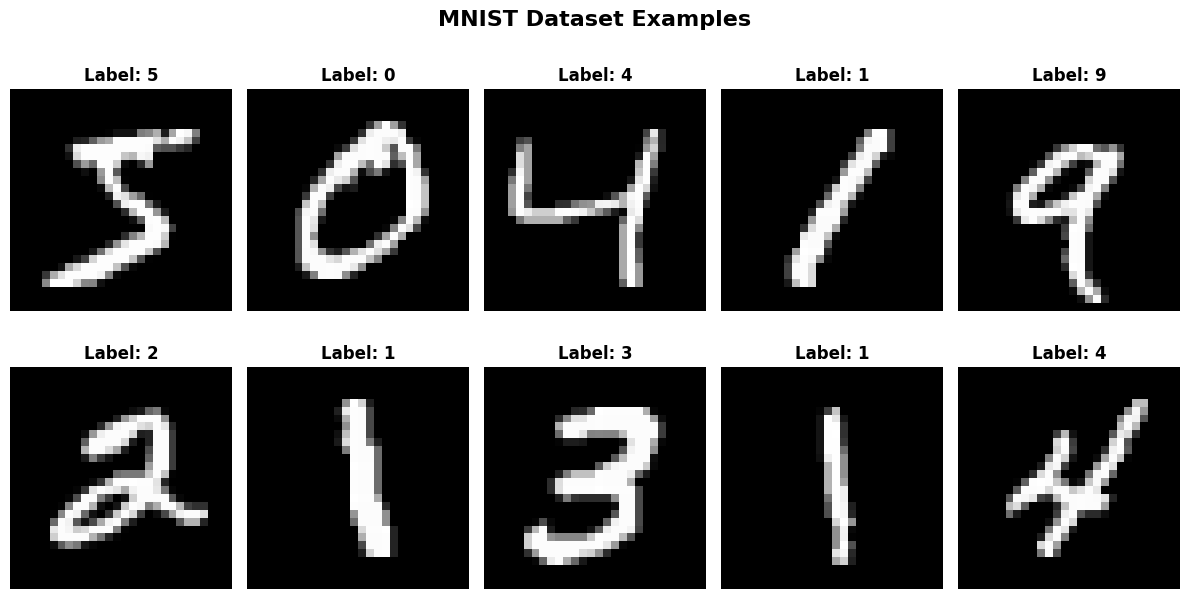

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# display some examples from the dataset
plt.figure(figsize=(12, 6.5))
plt.suptitle("MNIST Dataset Examples", fontsize=16, fontweight="bold")
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {int(y[i])}", fontsize=12, fontweight="bold")
    plt.axis("off")

plt.tight_layout()
plt.show()

The MNIST dataset consists of 70,000 grayscale images where each one represents a single handwritten digit. The images have a fixed resolution of 28x28 pixels and each image contains a vector of 784 numerical features. Each feature represents one pixel intensity, and the labels are which number each image corresponds to, with classes from 0 to 9.

**3. Split the dataset into a training, validation, and test set. You should use 70% of the data for training, 15% for validation, and 15% for testing.**

In [48]:
from sklearn.model_selection import train_test_split

# split the data into training and temp sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# split temp into validation and testing sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# normalize the data
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

print("Train shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)

Train shape: (49000, 784) (49000,)
Validation shape: (10500, 784) (10500,)
Test shape: (10500, 784) (10500,)


**(a) Display the class distribution in the training, validation, and test sets**

In [49]:
import numpy as np
import pandas as pd

def show_class_distribution(labels, name):
    classes, counts = np.unique(labels, return_counts=True)
    proportions = counts / counts.sum()

    df = pd.DataFrame({
        "Class": classes,
        "Count": counts,
        "Proportion": proportions
    })

    print(f"\n{name} class distribution:")
    display(df)

show_class_distribution(y_train, "Training")
show_class_distribution(y_val, "Validation")
show_class_distribution(y_test, "Test")


Training class distribution:


,Class,Count,Proportion
0,0,4832,0.098612
1,1,5514,0.112531
2,2,4893,0.099857
3,3,4999,0.102020
4,4,4777,0.097490
5,5,4419,0.090184
6,6,4813,0.098224
7,7,5105,0.104184
8,8,4777,0.097490
9,9,4871,0.099408



Validation class distribution:


,Class,Count,Proportion
0,0,1036,0.098667
1,1,1182,0.112571
2,2,1048,0.099810
3,3,1071,0.102000
4,4,1023,0.097429
5,5,947,0.090190
6,6,1031,0.098190
7,7,1094,0.104190
8,8,1024,0.097524
9,9,1044,0.099429



Test class distribution:


,Class,Count,Proportion
0,0,1035,0.098571
1,1,1181,0.112476
2,2,1049,0.099905
3,3,1071,0.102000
4,4,1024,0.097524
5,5,947,0.090190
6,6,1032,0.098286
7,7,1094,0.104190
8,8,1024,0.097524
9,9,1043,0.099333


**(b) Do you need to stratify your split? Why or why not?**

Stratification is not necessary for this dataset, but it is a good practice to uphold for multiclass classification problems. Stratified sampling is when the population is divided into groups, and then samples are randomly selected from the group in proportion to their representation in the entire population. This is particularly important when a dataset is imbalanced, because a completely random split might mean that the training set is not actually representative of the data. Since the MNIST dataset is balanced, with each digit having nearly the same number of samples, a random split without stratification would be fine too.

**4. Implement softmax regression with gradient descent using vectorised NumPy code. Implement early stopping based on the validation set. Do not use scikit-learn for this task – only NumPy and basic Python.**


To implement softmax regression from scratch with NumPy, I firstly added a bias term to the input features so that the model could learn an intercept. The MNIST dataset faces a multiclass classification problem because there are 10 possible digit classes. As such, I decided to turn the labels into one-hot encoded vectors after researching how to handle categorical attributes both online and in the Hands-on Machine Learning textbook. One-Hot Encoding is a preprocessing technique that converts categorical variables ino a numeric format for machine learning models to understand more clearly. Each category is represented as a separate binary columnm, with 1 meaning the value is equal to the category (hot) and 0 meaning it is not equal (cold). 


The model uses the softmax function to convert class scores into probabilities, which as mentioned works with MNIST because it is a multiclass classification problem with 10 classes. I used cross-entropy loss as instructed in the assignment as it works well for comparing predicted class probabilities against the real labels. I then trained the model using batch gradient descent because it let me compute the gradient across the full training set with vectorised NumPy operations, which made the implementation easier to follow. As requried, I also used early stopping based on validation loss so that training would stop once the model stopped improving on unseen data, which helps to reduce overfitting.

In [100]:
import numpy as np

# making sure the labels are ints before one-hot encoding
y_train = y_train.astype(int)
y_val = y_val.astype(int)

# adding a bias column so the model can learn an intercept as well
X_train_bias = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_val_bias = np.c_[np.ones((X_val.shape[0], 1)), X_val]

# one-hot encoding the labels for softmax regression
num_classes = 10
y_train_one_hot = np.eye(num_classes)[y_train]
y_val_one_hot = np.eye(num_classes)[y_val]

# starting the weights off small and random
rng = np.random.default_rng(42)
weights = rng.normal(0, 0.01, size=(X_train_bias.shape[1], num_classes))

# helper function for softmax
def softmax(score_matrix):
    # subtracting the row max prevents exponentials blowup
    shifted_scores = score_matrix - np.max(score_matrix, axis=1, keepdims=True)
    exp_scores = np.exp(shifted_scores)
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

# helper function for cross-entropy loss
def cross_entropy_loss(y_true, y_pred):
    # clipping avoids log(0), which would ruin everything :(
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(np.sum(y_true * np.log(y_pred), axis=1))

# training settings
learning_rate = 0.1
max_epochs = 1000
patience = 10

# storing the loss values so we can plot them later
training_loss_history = []
validation_loss_history = []

# early stopping setup
best_weights = weights.copy()
best_val_loss = np.inf
epochs_without_improvement = 0

for epoch in range(max_epochs):
    # scores are just X dot W
    train_scores = X_train_bias @ weights
    val_scores = X_val_bias @ weights

    # convert scores into probabilites with softmax
    train_probs = softmax(train_scores)
    val_probs = softmax(val_scores)

    # calculate the cross-entropy loss for both sets
    train_loss = cross_entropy_loss(y_train_one_hot, train_probs)
    val_loss = cross_entropy_loss(y_val_one_hot, val_probs)

    training_loss_history.append(train_loss)
    validation_loss_history.append(val_loss)

    # checking whether validation loss improved
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = weights.copy()
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # if validation loss stops improving, stop early
    if epochs_without_improvement >= patience:
        print(f"Early stopping triggered at epoch {epoch + 1}")
        break

    # vectorised gradient for softmax regression
    gradient = (X_train_bias.T @ (train_probs - y_train_one_hot)) / X_train_bias.shape[0]

    # gradient descent update
    weights = weights - learning_rate * gradient

    # printing every 10 epochs so it is a little easier to see
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"training loss = {train_loss:.4f}, "
            f"validation loss = {val_loss:.4f}"
        )

# restoring the best weights seen during training
weights = best_weights

Epoch 10: training loss = 1.5916, validation loss = 1.5955
Epoch 20: training loss = 1.2059, validation loss = 1.2121
Epoch 30: training loss = 1.0028, validation loss = 1.0103
Epoch 40: training loss = 0.8801, validation loss = 0.8884
Epoch 50: training loss = 0.7980, validation loss = 0.8069
Epoch 60: training loss = 0.7389, validation loss = 0.7482
Epoch 70: training loss = 0.6941, validation loss = 0.7038
Epoch 80: training loss = 0.6589, validation loss = 0.6688
Epoch 90: training loss = 0.6303, validation loss = 0.6404
Epoch 100: training loss = 0.6065, validation loss = 0.6169
Epoch 110: training loss = 0.5864, validation loss = 0.5970
Epoch 120: training loss = 0.5692, validation loss = 0.5799
Epoch 130: training loss = 0.5542, validation loss = 0.5651
Epoch 140: training loss = 0.5409, validation loss = 0.5520
Epoch 150: training loss = 0.5292, validation loss = 0.5404
Epoch 160: training loss = 0.5187, validation loss = 0.5301
Epoch 170: training loss = 0.5092, validation los

Training and validation loss was checked at each epoch, as seen above. This helped to visualise the learning process a bit more. 

**(a) Display a plot showing how the training and validation loss changes over time for your model.**

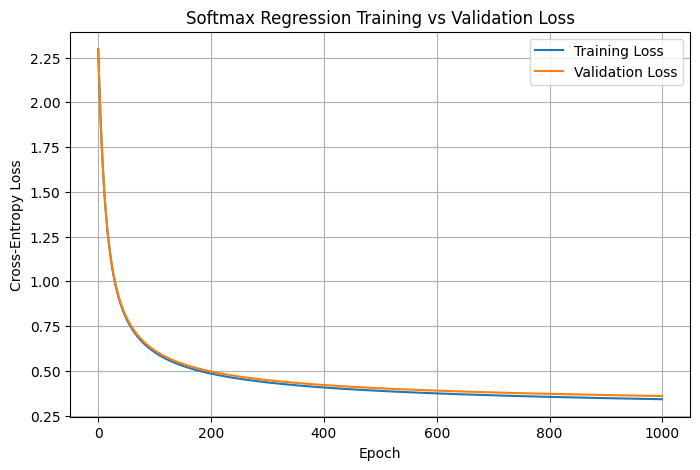

In [101]:
plt.figure(figsize=(8, 5))
plt.plot(training_loss_history, label="Training Loss")
plt.plot(validation_loss_history, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Softmax Regression Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

**(b) What do you observe? Is this what you expected?**

As the number of epochs increases, both the training and validation loss gradually decrease until they plateau. The two curves are almost identical for the first 25 or so epochs, although after that the validation loss becomes slightly higher than the training loss. This behaviour is expected because machine learning models usually perform a little better on the training data than on unseen validation data. The small difference between the curves suggests that overfitting was not a major issue. I was also not too surprised by the similar decrease in both curves, since MNIST is a well-structured dataset, the softmax regression model is relatively simple, and early stopping helped reduce overfitting.

I was not initially expecting such smooth curves, but after reflecting on it, the smoothness made sense because I used batch gradient descent rather than a method with more randomness, like stochastic gradient descent.

**5. Fit a sklearn.linear model.LogisticRegression model to the data. Do not apply regularisation. Compare the performance of your softmax regression model to the scikit-learn model**

Since scikit-learn's LogisticRegression automatically applies regularisation by default, I set C to a really large number to offset the effect of the automated regularisation.

In [102]:
from sklearn.linear_model import LogisticRegression
import numpy as np

sklearn_log_reg = LogisticRegression(
    C=1e12, # to offset automatic regularisation
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

sklearn_log_reg.fit(X_train, y_train)

# sklearn model predictions
sklearn_test_predictions = sklearn_log_reg.predict(X_test)

# custom softmax model predictions
X_test_bias = np.c_[np.ones((X_test.shape[0], 1)), X_test]
softmax_test_scores = X_test_bias @ weights
softmax_test_predictions = np.argmax(softmax_test_scores, axis=1)

The predictions from above are used in the following sections to compare the performance between my softmax regression model and the scikit-learn model.

**(a) Display a confusion matrix for each model.**

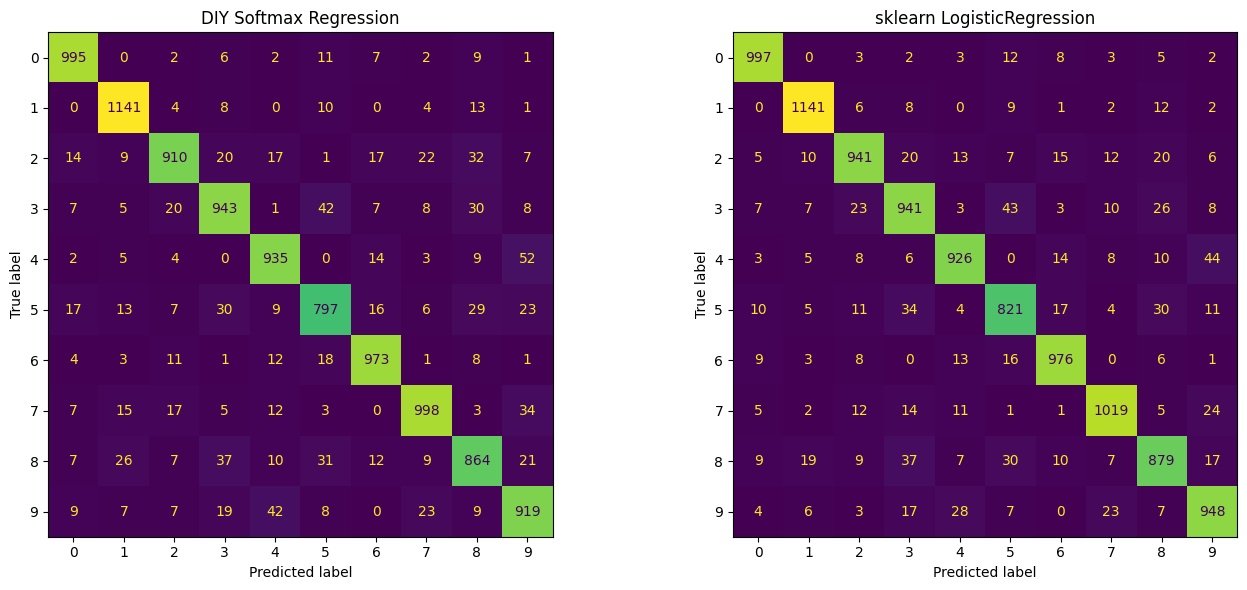

In [103]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

softmax_conf_matrix = confusion_matrix(y_test, softmax_test_predictions)
sklearn_conf_matrix = confusion_matrix(y_test, sklearn_test_predictions)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay(softmax_conf_matrix).plot(ax=axes[0], colorbar=False)
axes[0].set_title("DIY Softmax Regression")

ConfusionMatrixDisplay(sklearn_conf_matrix).plot(ax=axes[1], colorbar=False)
axes[1].set_title("sklearn LogisticRegression")

plt.tight_layout()
plt.show()

**(b) Show appropriate evaluation metrics for both models.**

In [104]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

def get_model_metrics(true_labels, predicted_labels, model_name):
    accuracy = accuracy_score(true_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0
    )
    
    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

metrics_table = pd.DataFrame([
    get_model_metrics(y_test, softmax_test_predictions, "DIY Softmax Regression"),
    get_model_metrics(y_test, sklearn_test_predictions, "sklearn LogisticRegression")
])

metrics_table = metrics_table.set_index("Model").round(4)
metrics_table

,Accuracy,Precision,Recall,F1-score
Model,,,,
DIY Softmax Regression,0.9024,0.9022,0.9024,0.9021
sklearn LogisticRegression,0.9132,0.9131,0.9132,0.9131


**(c) Comment on the results. Are they what you expected? Why or why not?**

The sklearn model did better than my DIY model in all metrics, namely accuracy, precision, recall, and f1-score. Both models did perform relatively well with a small gap in metrics. This difference in results was also seen in the confusion matrix. I expected my model to not out-perform the sklearn model as it is highly optimised and refined.

Initially, I ran my model on 200 epochs. WIth this, my softmax regression model predicted a 0 correctly 975 times, whereas the sklearn model predicted 0 correctly 997 times. It also had 87% accuracy is pretty reliable, demonstrating that the softmax regression algorithm was correctly implemented.

However, after thinking about performance more, I decided to increase the number of epochs to 1000. This took a lot of time to run all my cells, as expected, however it increased my performance by a lot. Now the difference between my DIY model and the sklearn is even smaller. For example, both predict 1 correctly 1141 times according to the confusion matrices and their accuracy, precision, recall, and f1-score only differ by around 1%.

**6. Comment on how the performance of your softmax regression model compares to the logistic regression model from scikit-learn.**

As mentioned in the earlier step, my model did not perform as well as the skikit-learn logistic regression. However, my model did perform reasonably well on the MNIST dataset. This proves that the softmax regression algorithm was correctly implemented and reasonably optimised by one-hot encoding and batch gradient descent. Increasing the number of training epochs also helped reduced the gap in performance, and I assume that more epochs would continue to improve my model as it seems it hasn't fully converged due to the early stopping. 

Another factor that might be impacting the performance of my model is the learning rate. The learning rate is what controls how big each step of gradient descent is. Maybe if I tried to adjust the learning rate more, it would've been easier for me to find where the model converges.

## Part 2: Support Vector Machine Regression

**1. Write a function that can generate a random toy n-degree polynomial dataset of the form, $y = \sum_{k=0}^{n} a_k x^k + \epsilon$ where x ∈ [−3, 3], $a_k$ ∼ U(0, 1), and $\epsilon$ ∼ N (0, 1). Your function should take two arguments: degree, and n_samples. Show your function works by plotting some generated datasets.**

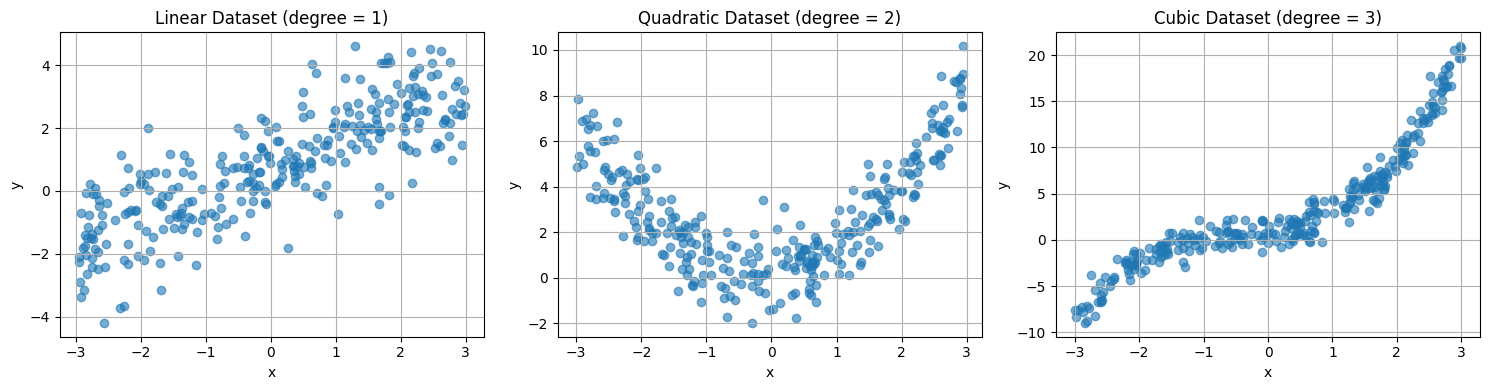

In [130]:
import numpy as np
import matplotlib.pyplot as plt

def generate_polynomial_dataset(degree, n_samples):
    # generate x values between -3 and 3
    x_vals = np.random.uniform(-3, 3, n_samples)

    # generate random coefficients a_0 up to a_degree from U(0, 1)
    coeffs = np.random.uniform(0, 1, degree + 1)

    # generate the noise term epsilon from N(0, 1)
    noise_term = np.random.normal(0, 1, n_samples)

    # start y off at 0, then build the polynomial up term by term
    y_vals = np.zeros(n_samples)
    for power in range(degree + 1):
        y_vals += coeffs[power] * (x_vals ** power)

    # add the noise at the end so it is not too perfectly clean
    y_vals += noise_term

    return x_vals, y_vals

# just testing that the function works for a few different degrees
x_linear, y_linear = generate_polynomial_dataset(degree=1, n_samples=300)
x_quadratic, y_quadratic = generate_polynomial_dataset(degree=2, n_samples=300)
x_cubic, y_cubic = generate_polynomial_dataset(degree=3, n_samples=300)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(x_linear, y_linear, alpha=0.6)
plt.title("Linear Dataset (degree = 1)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

plt.subplot(1, 3, 2)
plt.scatter(x_quadratic, y_quadratic, alpha=0.6)
plt.title("Quadratic Dataset (degree = 2)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

plt.subplot(1, 3, 3)
plt.scatter(x_cubic, y_cubic, alpha=0.6)
plt.title("Cubic Dataset (degree = 3)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

plt.tight_layout()
plt.show()

As shown above, I made a function that randomly generated polynomial datasets that aligned with the requirements given in the assignment. To test the function, I checked out how it worked on degrees of 1, 2, and 3 respectively to see if they looked like linear, quadratic, and cubic datasets respectively. Because the polynomial coefficients are randomly generated each time, when I ran the code cell multiple times, different runs had very different looking appearances. This variation is expected however because of the noise, and the datasets generally look like the degrees they are. 

**2. Generate three toy datasets using your function: a linear, a quadratic, and cubic dataset. Use n_samples = 1000. Make sure you have a training and test set for each dataset.**

In [135]:
from sklearn.model_selection import train_test_split

# generating the three toy datasets with 1000 samples each
x_linear, y_linear = generate_polynomial_dataset(degree=1, n_samples=1000)
x_quadratic, y_quadratic = generate_polynomial_dataset(degree=2, n_samples=1000)
x_cubic, y_cubic = generate_polynomial_dataset(degree=3, n_samples=1000)

# sklearn likes 2D feature arrays, so reshaping x into column vectors
x_linear = x_linear.reshape(-1, 1)
x_quadratic = x_quadratic.reshape(-1, 1)
x_cubic = x_cubic.reshape(-1, 1)

# splitting each dataset into training and test sets
x_linear_train, x_linear_test, y_linear_train, y_linear_test = train_test_split(
    x_linear, y_linear, test_size=0.2, random_state=42
)

x_quadratic_train, x_quadratic_test, y_quadratic_train, y_quadratic_test = train_test_split(
    x_quadratic, y_quadratic, test_size=0.2, random_state=42
)

x_cubic_train, x_cubic_test, y_cubic_train, y_cubic_test = train_test_split(
    x_cubic, y_cubic, test_size=0.2, random_state=42
)


As shown above, I generated three toy datasets based on my function from step 1 with 1000 samples each. Because sklearn needs the input features to be 2D arrays, I made the shape of each set of x-values into a column vector before splitting data into training and testing. Then I decided to use an 80/20 split so that I could use each dataset for fitting the model later.

**3. Experiment with fitting a sklearn.svm.SVR model to each of the three datasets using kernel=’linear’, kernel=’poly’ and kernel=’rbf’.**

In [139]:
from sklearn.svm import SVR

# storing everything in one place so it is easier to loop through later
toy_datasets = {
    "Linear": (x_linear_train, x_linear_test, y_linear_train, y_linear_test),
    "Quadratic": (x_quadratic_train, x_quadratic_test, y_quadratic_train, y_quadratic_test),
    "Cubic": (x_cubic_train, x_cubic_test, y_cubic_train, y_cubic_test)
}

svr_kernels = ["linear", "poly", "rbf"]

# saving fitted models here
fitted_svr_models = {}

for dataset_name, (x_train_split, x_test_split, y_train_split, y_test_split) in toy_datasets.items():
    fitted_svr_models[dataset_name] = {}

    for kernel_name in svr_kernels:
        # keeping the settings pretty standard for now
        # for poly, degree=3 is the sklearn default anyway, but I am stating it clearly
        if kernel_name == "poly":
            svr_model = SVR(kernel=kernel_name, degree=3)
        else:
            svr_model = SVR(kernel=kernel_name)

        svr_model.fit(x_train_split, y_train_split)
        fitted_svr_models[dataset_name][kernel_name] = svr_model


**(a) Show plots of the fitted regression function for each kernel and each dataset.**

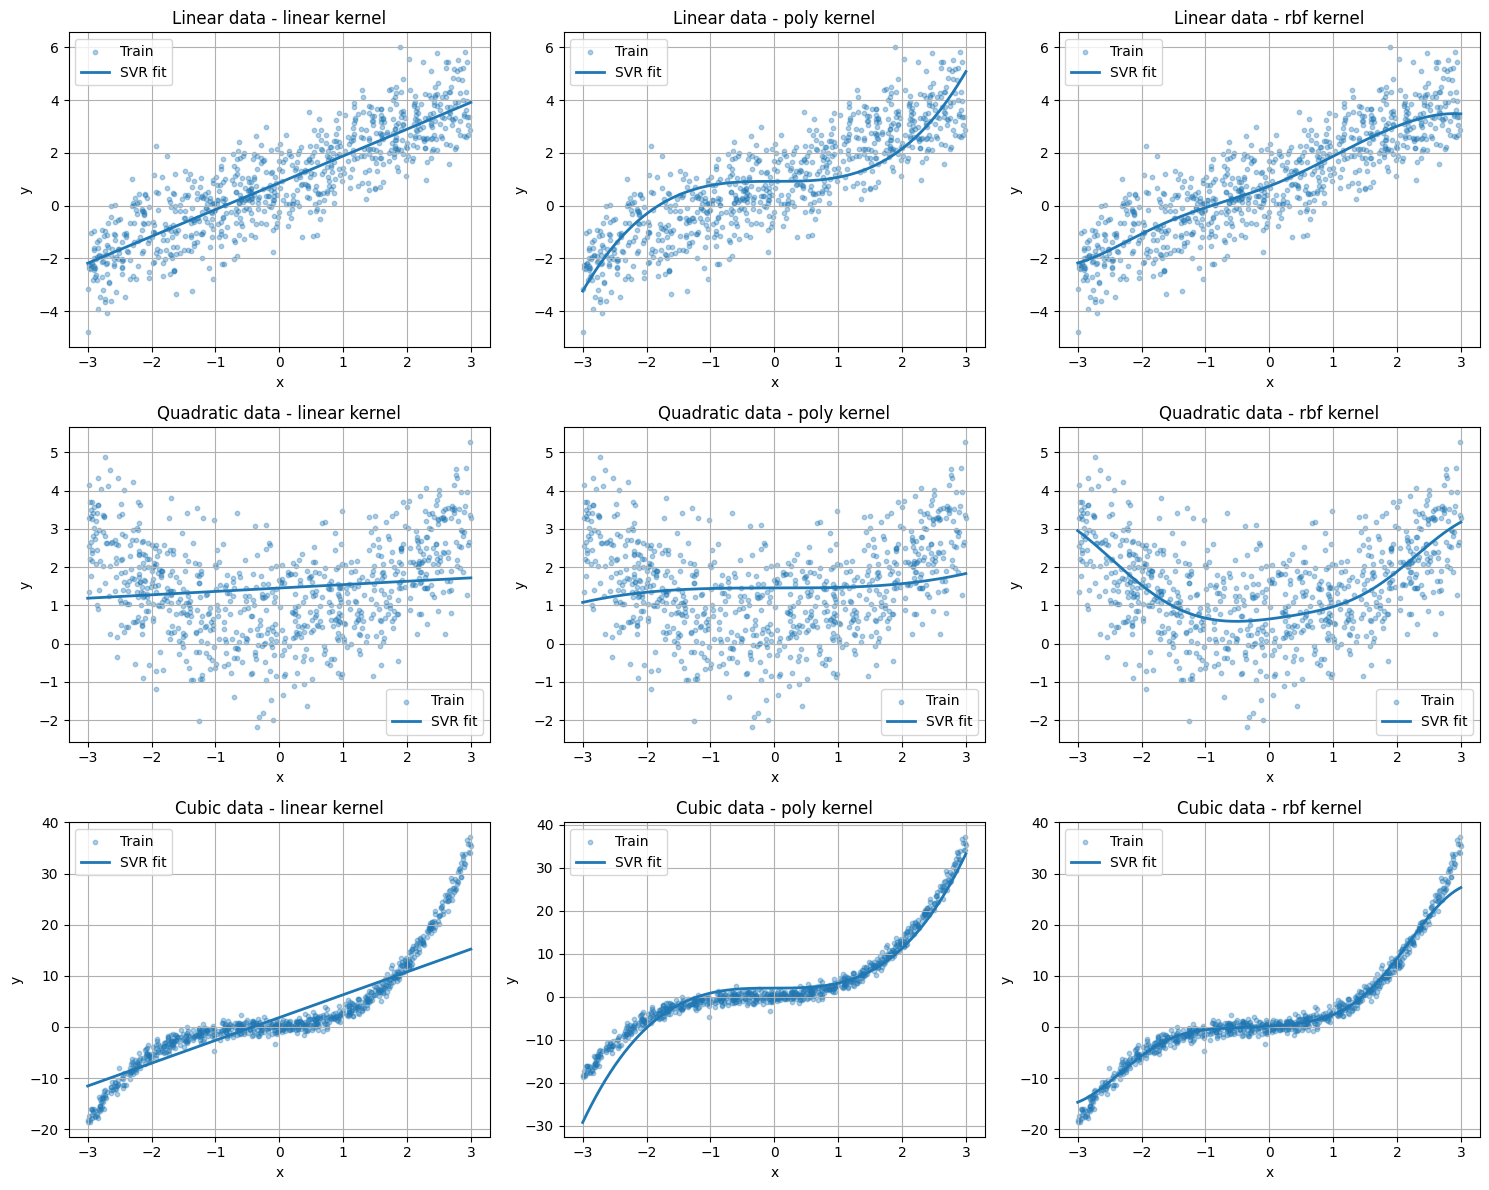

In [142]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 12))

plot_counter = 1

for dataset_name, (x_train_split, x_test_split, y_train_split, y_test_split) in toy_datasets.items():
    for kernel_name in svr_kernels:
        plt.subplot(3, 3, plot_counter)

        # plotting the training data
        plt.scatter(x_train_split, y_train_split, alpha=0.35, s=10, label="Train")

        # making a smooth x-grid so the fitted function looks clean
        x_plot_grid = np.linspace(-3, 3, 500).reshape(-1, 1)

        # getting predictions from the fitted model
        fitted_model = fitted_svr_models[dataset_name][kernel_name]
        y_plot_predictions = fitted_model.predict(x_plot_grid)

        # plotting the fitted regression function
        plt.plot(x_plot_grid, y_plot_predictions, linewidth=2, label="SVR fit")

        plt.title(f"{dataset_name} data - {kernel_name} kernel")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.grid(True)
        plt.legend()

        plot_counter += 1

plt.tight_layout()
plt.show()

**(b) Comment on the results. Are they what you expected?**

The linear kernel performed best on the linear data. This is expected because the linear data correlates to the linear relationship. The linear kernel however definitely underfit both the qudratic and cubic data since the straight line was too simple to fit the curved data.

The polynomial kernel did seem to identify a pattern in the linear data, however the curved shape seemed to be overfitting the linear data. It roughly followed the shape of the cubic dataset with slight underfitting, and strangely didn't match the quadratic dataset well. I expected the poly kernel to perform better on the quadratic dataset than it did.

The Radial Basis Functional (RBF) kernel performed best on all the datasets. While it slightly overfitted the linear dataset by introduces small curves towards the right side of the graph, it was the closest match to the expected shapes of quadratic and cubic datasets. This aligns with what I would expect as the RBF is a popular kernel used to learn diverse complex patterns.

**4. Perform grid-search with k-fold cross-validation (k = 5) on at least three hyperparameters (including kernel) with two different values each (2<sup>3</sup> = 8 total combinations) for your cubic dataset.**

In [146]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
import pandas as pd

# setting up the parameter grid for the cubic dataset
svr_param_grid = {
    "kernel": ["poly", "rbf"],
    "C": [0.1, 1.0],
    "epsilon": [0.1, 0.5]
}

# base SVR model
base_svr_model = SVR()

# 5-fold cross-validation grid search
cubic_grid_search = GridSearchCV(
    estimator=base_svr_model,
    param_grid=svr_param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# fitting only on the cubic training set
cubic_grid_search.fit(x_cubic_train, y_cubic_train)

print("Best parameters:", cubic_grid_search.best_params_)
print("Best cross-validation score:", cubic_grid_search.best_score_)

Best parameters: {'C': 1.0, 'epsilon': 0.1, 'kernel': 'rbf'}
Best cross-validation score: -3.054650623979022


**(a) What hyperparameters did you choose? How many models did you fit in total?**

As asked in the task, I performed a grid serach with 5-fold cross validation. The three hyperparameters I used were the kernel, C, and epsilon. I tested each hyperparameter at two values, meaning that there were 8 total combinations of parameters. 

- kernel: "poly", "rbf"
- C: 0.1, 1.0
- epsilon: 0.1, 0.5

For the kernel, I decided to test both poly and rbf since the linear kernel clearly didn't fit the cubic dataset well in the previous step. Fo C and epsilon, I picked two different values to compare the difference between smaller and larger values.

There was a total of 40 model fits since I used k=5 for my cross-validation and 8x5=40.

**(b) Present your results for the optimal hyperparameter combination**

As seen in the earlier code cell for part 4, the optimal hyperparameter combination was C = 1.0, epsilon = 0.1, and kernel = rbf. This combination of hyperparameters gave the best cross-validation score across the 8 tested combinations. The score was namely -3.054650623979022. 

The cross-validation metric was derived from the negative mean squared error (MSE). I decided to use this because the optimal combination would minimise the prediction error. MSE is commonly used as a metric for regression because it shows the average squared difference between the real and predicted values, while also penalising larger errors heavily. The best model is the one whose score is closest to zero, which is how my cross-validation score was obtained.

**5. Given your optimal model found in the previous step, evaluate your model on the test set. Present your results.**

In [147]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

# best model from grid search
best_cubic_svr = cubic_grid_search.best_estimator_

# test set predictions
y_cubic_test_pred = best_cubic_svr.predict(x_cubic_test)

# evaluation metrics
cubic_test_mse = mean_squared_error(y_cubic_test, y_cubic_test_pred)
cubic_test_mae = mean_absolute_error(y_cubic_test, y_cubic_test_pred)
cubic_test_r2 = r2_score(y_cubic_test, y_cubic_test_pred)

test_results = pd.DataFrame({
    "Metric": ["MSE", "MAE", "R-squared"],
    "Value": [cubic_test_mse, cubic_test_mae, cubic_test_r2]
}).round(4)

test_results

,Metric,Value
0,MSE,2.5822
1,MAE,1.1119
2,R-squared,0.9773


Based on the optimal hyperparameters found in step 4, namely kernel= rbf, C = 1.0, and epsilon = 0.1, I evaluated my model on the test set. The evaluation metrics I decided to pick were mean squared error (MSE), mean absolute error (MAE) and R-squared.

MSE measures the average squared difference between the predicted value and real value for a regression model. On the other hand, MAE is similar and measures the average magnitude of errors. The difference between these two is that MSE is sensitive to outliers, so both are good to use in conjunction to see how the model performs with outliers. Finally, the R-squared shows the proportion of variance due to independent variables in a regression model.

As shown above, MSE = 2.5822. The lower the value the better as it indicates higher accuracy. The MAE = 1.1119, which similar to MSE, is a good indicator as the closer to 0 the better. The value achieved means that each predicted value varied from the true dataset value by about 1 unit. Finally, R-squared ranges from 0 to 1, with a value of 1 indicting a very strong fit to the regression line. Since my R-squared = 0.9773, this indicates strong perfomance of the model.

Thus, based on the chosen metrics, I believe the optimal model I found performs very well on the test set, emphasising the importance of choosing your hyperparameters selectively. As a final visual demonstration of the model performance, I've plotted a figure that shows my best SVM fit on the cubic dataset.


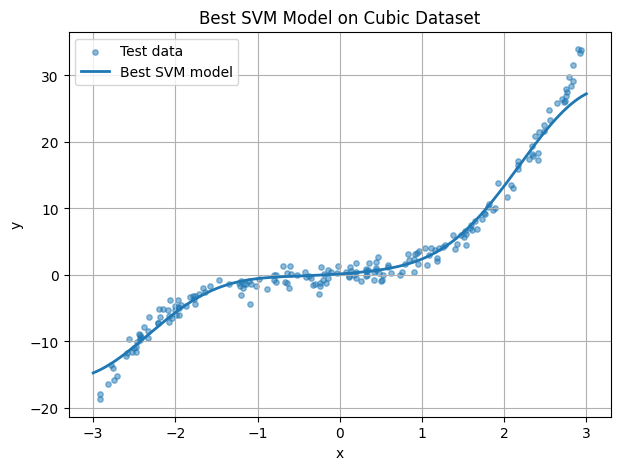

In [151]:
plt.figure(figsize=(7, 5))

plt.scatter(x_cubic_test.ravel(), y_cubic_test, alpha=0.5, s=15, label="Test data")

x_plot_grid = np.linspace(-3, 3, 500).reshape(-1, 1)
y_plot_best = best_cubic_svr.predict(x_plot_grid)

plt.plot(x_plot_grid.ravel(), y_plot_best, linewidth=2, label="Best SVM model")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Best SVM Model on Cubic Dataset")
plt.grid(True)
plt.legend()
plt.show()